In [12]:
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

In [2]:
IMG_SIZE = 256
BATCH_SIZE = 32


train_dataset = tf.keras.utils.image_dataset_from_directory(
    'lung_subset_small',
    subset='training',
    validation_split=0.1,
    seed=123,
    image_size=(256, 256),
    batch_size=32
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    'lung_subset_small',
    subset='validation',
    validation_split=0.1,
    seed=123,
    image_size=(256, 256),
    batch_size=32
)

print(train_dataset.class_names)

Found 2400 files belonging to 3 classes.
Using 2160 files for training.
Found 2400 files belonging to 3 classes.
Using 240 files for validation.
['lung_aca', 'lung_n', 'lung_scc']


In [3]:
for images, labels in train_dataset.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Labels:", labels[:10].numpy())

Image shape: (32, 256, 256, 3)
Label shape: (32,)
Labels: [1 2 1 0 0 2 0 1 2 0]


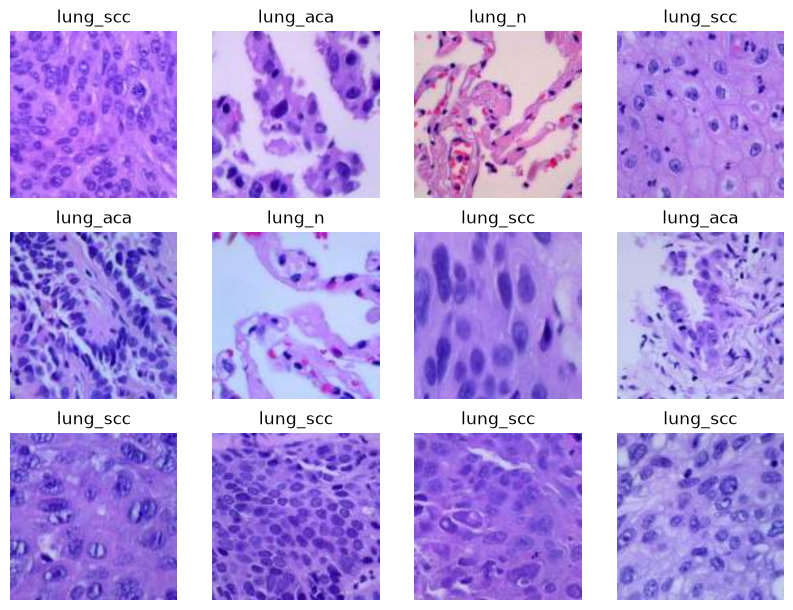

In [4]:
class_names = train_dataset.class_names

for images, labels in train_dataset.take(1):
    plt.figure(figsize=(10, 10))
    for i in range(12):
        ax = plt.subplot(4, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
    plt.show()

In [5]:
model = tf.keras.Sequential([
    
    layers.Input(shape=(256, 256, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.BatchNormalization(),

    layers.Dense(3, activation='softmax')
])

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [7]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [8]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=3
)

Epoch 1/3


c:\Users\bipin\OneDrive\Desktop\Lung disease predictionn\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


68/68 ━━━━━━━━━━━━━━━━━━━━ 277s 4s/step - accuracy: 0.7787 - loss: 0.5436 - val_accuracy: 0.6625 - val_loss: 11.4746
Epoch 2/3
68/68 ━━━━━━━━━━━━━━━━━━━━ 406s 5s/step - accuracy: 0.8444 - loss: 0.3887 - val_accuracy: 0.4625 - val_loss: 3.4172
Epoch 3/3
68/68 ━━━━━━━━━━━━━━━━━━━━ 222s 3s/step - accuracy: 0.8616 - loss: 0.3499 - val_accuracy: 0.8708 - val_loss: 0.3938


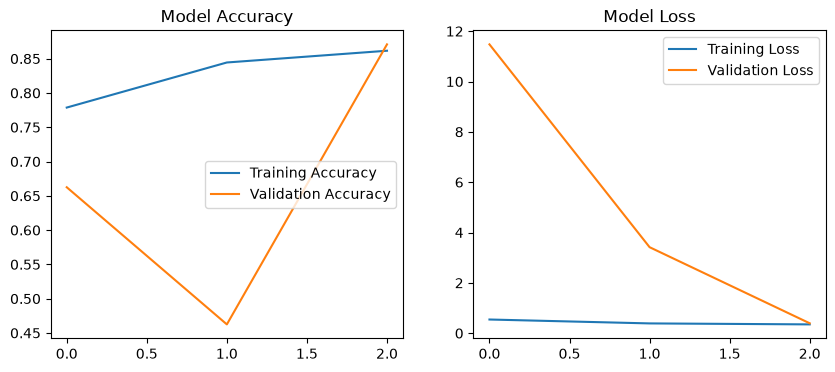

In [9]:
plt.figure(figsize=(10, 4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Model Accuracy')

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Model Loss')

plt.show()

In [10]:
loss , accuracy = model.evaluate(validation_dataset)

print('Loss:',loss)
print('Accuracy:',accuracy)

8/8 ━━━━━━━━━━━━━━━━━━━━ 8s 861ms/step - accuracy: 0.8708 - loss: 0.3938
Loss: 0.3937990069389343
Accuracy: 0.8708333373069763


In [13]:

y_true = []
y_pred = []

for images, labels in validation_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

cm = confusion_matrix(y_true, y_pred)



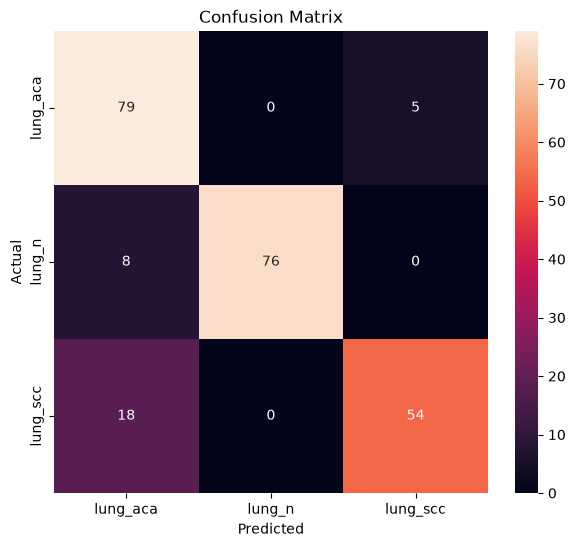

In [14]:
plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=train_dataset.class_names,
    yticklabels=train_dataset.class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [15]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=train_dataset.class_names
    )
)

              precision    recall  f1-score   support

    lung_aca       0.75      0.94      0.84        84
      lung_n       1.00      0.90      0.95        84
    lung_scc       0.92      0.75      0.82        72

    accuracy                           0.87       240
   macro avg       0.89      0.87      0.87       240
weighted avg       0.89      0.87      0.87       240



In [16]:
def predict_image(image_path):

    img = tf.keras.utils.load_img(
        image_path,
        target_size=(256, 256)
    )

    img_array = tf.keras.utils.img_to_array(img)

    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array)

    predicted_class = train_dataset.class_names[
        np.argmax(predictions[0])
    ]

    confidence = np.max(predictions[0]) * 100

    print("Prediction:", predicted_class)
    print("Confidence:", round(confidence, 2), "%")

In [20]:
predict_image("lung_subset_small/lung_scc/lungscc54.jpeg")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
Prediction: lung_scc
Confidence: 87.4 %


In [21]:
model.save('lung_disease_cnn.keras')